# How the binding model compares with other models

Three comparisons:

1. **Earlier attempts in the group.** PerceiverCPI (a published cross-attention compound-protein
   interaction model) and a graph-network classifier on protein language model embeddings were trained
   on M2OR before the paper's model was built. Their test scores are in `Tables/earlier_attempts.csv`,
   as each tool reported them. They used an older M2OR export and a single split, so they are context,
   not a matched comparison.
2. **Baselines on the paper's splits.** Simple models trained and tested on the same kind of stratified
   80/10/10 split as the paper's five runs, built the same way (`train_test_split`, stratified by label,
   seed = run), over the same 52,175 observations. They range from no structure at all (how often an
   odorant, or a receptor, binds in the training data) to gradient boosting on the same frozen ESM
   Cambrian and MoLFormer embeddings the binding model reads.
3. **Unseen receptors and unseen odorants.** A random split puts the same receptors and odorants in
   training and test, which rewards remembering them. The ancestral receptors are new sequences, so the
   relevant test is on receptors never seen in training. The baselines are evaluated there too.

The paper's model is evaluated on its own held-out test pairs (`model_runs`).

In [1]:
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split

import sys
REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Supplementary_Material"))
import robustness_checks as rc
from plotting_functions import custom_plots, FIGSIZE
from activation_figures import INK, MUTED, save

plt.rcParams.update(custom_plots())
plt.rcParams.update(rc.TEXT_SIZES)
RDLogger.DisableLog("rdApp.*")

PAIRS = REPO / "Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv"
PROTEIN_EMBEDDINGS = REPO / "Model_Inputs/Embeddings/proteins/m2or_esmc_300m_embeddings"
MOLECULE_EMBEDDINGS = REPO / "Model_Inputs/Embeddings/molecules/molformer_smiles_embeddings.pt"

TABLES = Path("Tables")
FIGURES = Path("Figures")
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

## 1. Earlier attempts

The test ROC AUC each tool reported, with the data and split recorded in the run's own settings.

In [2]:
earlier = pd.read_csv(TABLES / "earlier_attempts.csv")
earlier

,model,test_roc_auc,data,split,source
0,"PerceiverCPI, 150 epochs (setting 100)",0.892624,"older M2OR export, 46,563 pairs (M2OR_original...",one random 80/10/10 split,PerceiverCPI/M2OR_classification_150epochs_100...
1,"PerceiverCPI, 150 epochs (setting 150)",0.887806,"older M2OR export, 46,563 pairs (M2OR_original...",one random 80/10/10 split,PerceiverCPI/M2OR_classification_150epochs_150...
2,graph network + protein language model embeddings,0.756396,not recorded,not recorded,micro_olf/Output/eval.txt
3,graph network + protein language model embeddi...,0.549562,not recorded,not recorded,micro_olf/Output/42_eval.txt


## 2. Baselines on the paper's kind of split

Features are built once: the mean of the ESM Cambrian per-residue embedding of each sequence (BOS and
EOS removed), the pooled MoLFormer vector of each SMILES, and a Morgan fingerprint (radius 2, 1,024
bits). The prior baselines score a pair by the training binding rate of its odorant, of its receptor,
or of both (combined by logistic regression), smoothed towards the overall rate with one pseudo-pair.

In [3]:
pairs = pd.read_csv(PAIRS)
labels = pairs.Responsive.values.astype(int)

protein_vectors = {}
for path in glob.glob(str(PROTEIN_EMBEDDINGS / "*.npy")):
    sequence_id = os.path.basename(path).split(".")[0]
    protein_vectors[sequence_id] = np.load(path)[1:-1].mean(axis=0)
molecule_vectors = torch.load(MOLECULE_EMBEDDINGS, map_location="cpu", weights_only=False)
fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
fingerprints = {smiles: fingerprint_generator.GetFingerprintAsNumPy(Chem.MolFromSmiles(smiles))
                for smiles in pairs.SMILES.unique()}

protein_features = np.stack([protein_vectors[s] for s in pairs.seq_id])
molecule_features = np.stack([molecule_vectors[s].numpy() for s in pairs.SMILES])
fingerprint_features = np.stack([fingerprints[s] for s in pairs.SMILES]).astype(np.float32)
print(f"pairs {len(pairs):,}, positive rate {labels.mean():.4f}, receptors {pairs.seq_id.nunique()}, "
      f"odorants {pairs.smiles_id.nunique()}")

pairs 52,175, positive rate 0.0588, receptors 1399, odorants 754


In [4]:
def training_rate(train_rows, key):
    """Binding rate of each odorant or receptor in the training rows, smoothed with one pseudo-pair."""
    overall = labels[train_rows].mean()
    counts = pairs.iloc[train_rows].groupby(key).Responsive.agg(["sum", "count"])
    smoothed = (counts["sum"] + overall) / (counts["count"] + 1)
    return pairs[key].map(smoothed).fillna(overall).values


def log_odds(probability):
    probability = np.clip(probability, 1e-4, 1 - 1e-4)
    return np.log(probability / (1 - probability))


def baseline_scores(train_rows, seed):
    """Score every pair with each baseline, trained on `train_rows` only."""
    odorant_rate = training_rate(train_rows, "smiles_id")
    receptor_rate = training_rate(train_rows, "seq_id")
    both = np.column_stack([log_odds(odorant_rate), log_odds(receptor_rate)])
    prior_model = LogisticRegression().fit(both[train_rows], labels[train_rows])

    embeddings = np.hstack([protein_features, molecule_features])
    embedding_model = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, random_state=seed)
    embedding_model.fit(embeddings[train_rows], labels[train_rows])

    with_fingerprints = np.hstack([protein_features, fingerprint_features])
    fingerprint_model = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, random_state=seed)
    fingerprint_model.fit(with_fingerprints[train_rows], labels[train_rows])

    return {"odorant binding rate": odorant_rate,
            "receptor binding rate": receptor_rate,
            "odorant + receptor binding rates": prior_model.predict_proba(both)[:, 1],
            "ESM C + MoLFormer, gradient boosting": embedding_model.predict_proba(embeddings)[:, 1],
            "ESM C + Morgan fingerprint, gradient boosting": fingerprint_model.predict_proba(with_fingerprints)[:, 1]}


def evaluate(scores, test_rows, split, run):
    return [dict(split=split, run=run, model=name,
                 roc_auc=roc_auc_score(labels[test_rows], score[test_rows]),
                 pr_auc=average_precision_score(labels[test_rows], score[test_rows]))
            for name, score in scores.items()]

In [5]:
rows = []
all_rows = np.arange(len(labels))
for run in range(5):
    # The paper's procedure: stratified by label, 80% training, the rest halved into
    # validation and test, seed = run.
    train_rows, held_out = train_test_split(all_rows, test_size=0.2, stratify=labels, random_state=run)
    _, test_rows = train_test_split(held_out, test_size=0.5, stratify=labels[held_out], random_state=run)
    rows += evaluate(baseline_scores(train_rows, run), test_rows, "random (as in the paper)", run + 1)

paper_runs = pd.read_csv(rc.RUN_METRICS)
paper_runs = paper_runs[paper_runs.run.str.startswith("Run")]
for _, run in paper_runs.iterrows():
    rows.append(dict(split="random (as in the paper)", run=int(run.run.split("_")[1]),
                     model="binding model (paper)", roc_auc=float(run.roc_auc), pr_auc=float(run.pr_auc)))
random_split = pd.DataFrame(rows)

## 3. Unseen receptors and unseen odorants

The same baselines on splits that hold out whole receptors (grouped by UniProt accession, so a
receptor and its mutants are never split between training and test) or whole odorants: 80% of the
groups for training, the rest for testing, five seeds. The paper's model has not been retrained on
these splits; that needs a GPU, and it is the comparison these numbers are waiting for.

In [6]:
rows = []
for split, key in [("unseen receptors", "UniProt ID"), ("unseen odorants", "smiles_id")]:
    splitter = GroupShuffleSplit(n_splits=5, test_size=0.2, random_state=0)
    for run, (train_rows, test_rows) in enumerate(splitter.split(all_rows, labels, groups=pairs[key]), start=1):
        rows += evaluate(baseline_scores(train_rows, run), test_rows, split, run)
cold_splits = pd.DataFrame(rows)

comparison = pd.concat([random_split, cold_splits], ignore_index=True)
comparison.to_csv(TABLES / "model_comparison_runs.csv", index=False)
summary = (comparison.groupby(["split", "model"])[["roc_auc", "pr_auc"]]
           .agg(["mean", "std"]).round(3))
summary.columns = ["roc_auc_mean", "roc_auc_sd", "pr_auc_mean", "pr_auc_sd"]
summary = summary.reset_index()
summary.to_csv(TABLES / "model_comparison_summary.csv", index=False)
summary

,split,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd
0,random (as in the paper),"ESM C + MoLFormer, gradient boosting",0.914,0.009,0.529,0.022
1,random (as in the paper),"ESM C + Morgan fingerprint, gradient boosting",0.905,0.012,0.512,0.017
2,random (as in the paper),binding model (paper),0.911,0.011,0.494,0.013
3,random (as in the paper),odorant + receptor binding rates,0.870,0.007,0.437,0.011
4,random (as in the paper),odorant binding rate,0.789,0.014,0.239,0.018
5,random (as in the paper),receptor binding rate,0.806,0.017,0.366,0.009
6,unseen odorants,"ESM C + MoLFormer, gradient boosting",0.860,0.036,0.442,0.089
7,unseen odorants,"ESM C + Morgan fingerprint, gradient boosting",0.836,0.053,0.431,0.089
8,unseen odorants,odorant + receptor binding rates,0.825,0.056,0.394,0.070
9,unseen odorants,odorant binding rate,0.500,0.000,0.057,0.008


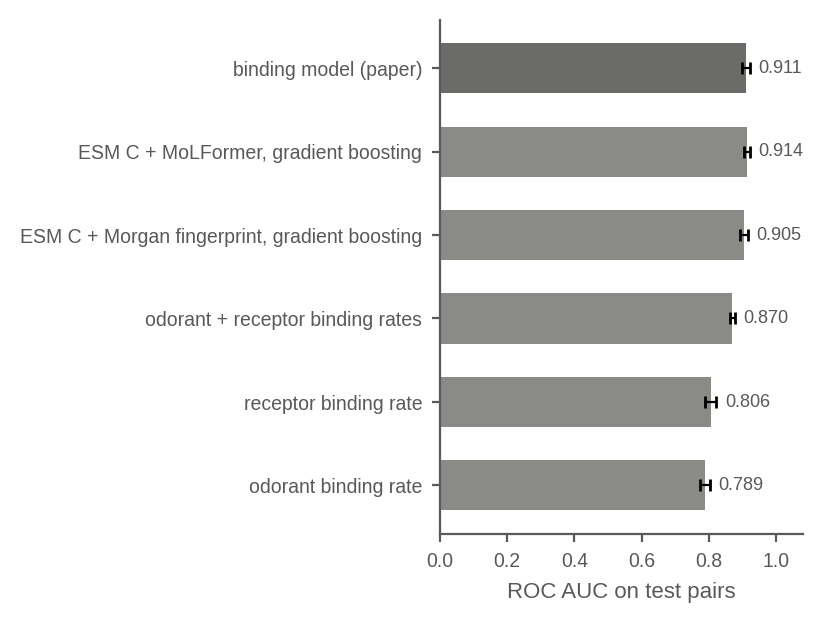

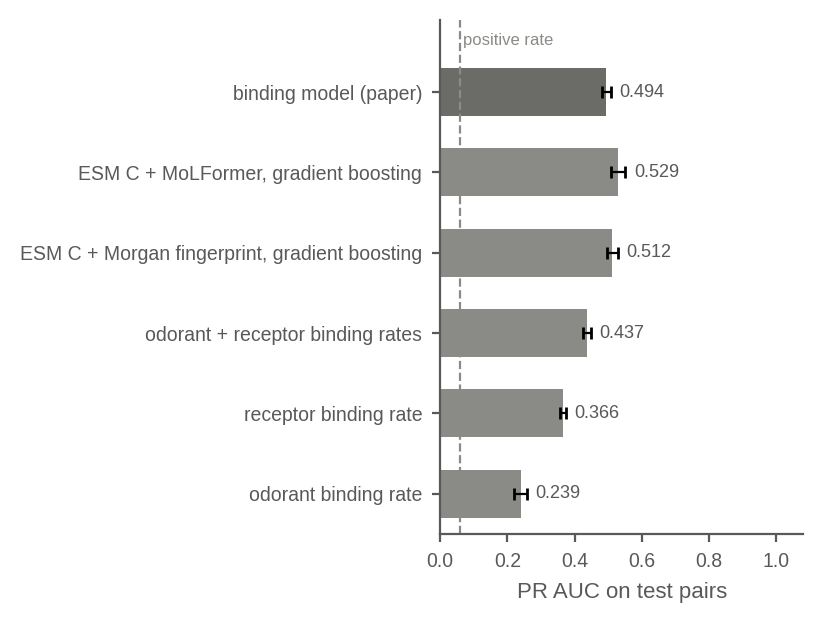

In [7]:
ORDER = ["binding model (paper)", "ESM C + MoLFormer, gradient boosting",
         "ESM C + Morgan fingerprint, gradient boosting", "odorant + receptor binding rates",
         "receptor binding rate", "odorant binding rate"]

for metric, label, file_name in [("roc_auc", "ROC AUC on test pairs", "model_comparison_roc_auc.svg"),
                                 ("pr_auc", "PR AUC on test pairs", "model_comparison_pr_auc.svg")]:
    figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
    shown = summary[summary.split == "random (as in the paper)"].set_index("model").loc[ORDER]
    positions = np.arange(len(shown))
    colours = [INK if name == "binding model (paper)" else MUTED for name in shown.index]
    axis.barh(positions, shown[f"{metric}_mean"], xerr=shown[f"{metric}_sd"], color=colours, height=0.6,
              error_kw=dict(lw=0.8, capsize=2))
    for y, value, spread in zip(positions, shown[f"{metric}_mean"], shown[f"{metric}_sd"]):
        axis.text(value + spread + 0.025, y, f"{value:.3f}", va="center", fontsize=6.5)
    if metric == "pr_auc":
        axis.axvline(labels.mean(), color=MUTED, lw=0.8, ls="--")
        axis.text(labels.mean() + 0.01, -0.55, "positive rate", fontsize=6, color=MUTED, va="bottom")
        axis.set_ylim(-0.9, len(shown) - 0.5)
    axis.set_yticks(positions)
    axis.set_yticklabels(shown.index, fontsize=7)
    axis.invert_yaxis()
    axis.set_xlim(0, 1.08)
    axis.set_xlabel(label, fontsize=8)
    axis.tick_params(axis="x", labelsize=7)
    save(figure, FIGURES / file_name, show=True)

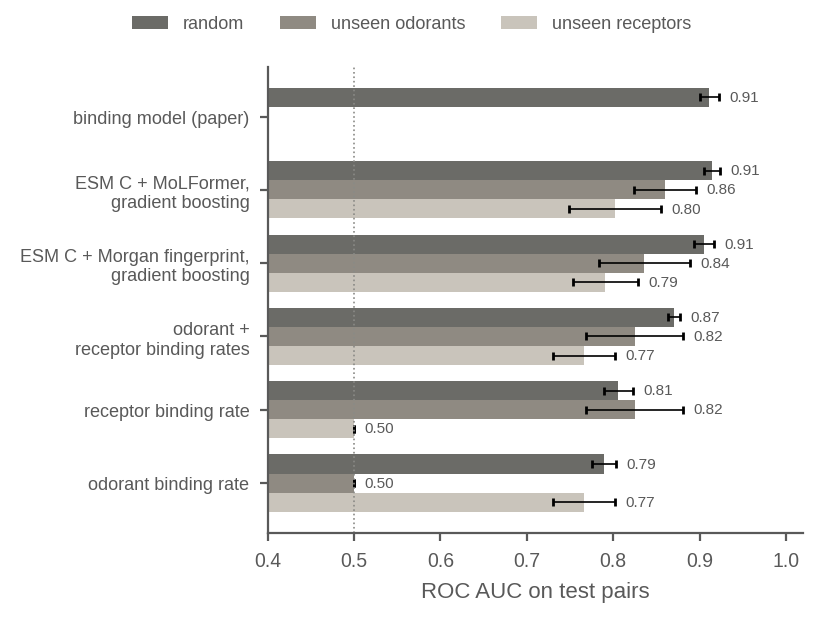

In [8]:
SPLITS = [("random (as in the paper)", "random", INK), ("unseen odorants", "unseen odorants", "#8f8a82"),
          ("unseen receptors", "unseen receptors", "#c9c4bb")]
figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
positions = np.arange(len(ORDER))
height = 0.26
for offset, (split, label, colour) in zip([-height, 0, height], SPLITS):
    shown = summary[summary.split == split].set_index("model").reindex(ORDER)
    axis.barh(positions + offset, shown.roc_auc_mean, xerr=shown.roc_auc_sd, height=height, color=colour,
              label=label, error_kw=dict(lw=0.6, capsize=1.5))
# Values are written after every bar is drawn, so no bar covers them.
for offset, (split, label, colour) in zip([-height, 0, height], SPLITS):
    shown = summary[summary.split == split].set_index("model").reindex(ORDER)
    for y, value, spread in zip(positions + offset, shown.roc_auc_mean, shown.roc_auc_sd):
        if np.isfinite(value):
            axis.text(value + spread + 0.012, y, f"{value:.2f}", va="center", fontsize=5.5, zorder=5)
axis.axvline(0.5, color=MUTED, lw=0.6, ls=":")
axis.set_yticks(positions)
axis.set_yticklabels([name.replace(", ", ",\n").replace(" + receptor", " +\nreceptor") for name in ORDER], fontsize=6.5)
axis.invert_yaxis()
axis.set_xlim(0.4, 1.02)
axis.set_xlabel("ROC AUC on test pairs")
figure.legend(frameon=False, fontsize=6.5, loc="outside upper center", ncol=3)
save(figure, FIGURES / "model_comparison_by_split.svg", show=True)

On splits like the paper's, the binding model is in the range of a gradient-boosted tree on the same
frozen embeddings, and knowing only how often each odorant and each receptor binds already reaches a
ROC AUC near 0.87. That is a property of M2OR: binding is concentrated in a few broadly tuned
receptors and frequently active odorants, and a random split rewards learning them. The numbers on
unseen receptors are the ones that matter for the ancestral predictions, and the binding model has
still to be evaluated there.